Load data Set using kaggle api

In [ ]:
import os
import pandas as pd
from kaggle.api.kaggle_api_extended import KaggleApi

# 1. Hardcode your Kaggle credentials directly

api = KaggleApi()
api.authenticate()

# 2. Initialize and authenticate
api = KaggleApi()
api.authenticate()
print("Authenticated successfully!")

# 3. Download the dataset
dataset_slug = 'shubhamdamai/ab-testing-analysis-facebook-vs-adword'
print("Downloading dataset...")
api.dataset_download_files(dataset_slug, path='.', unzip=True)

# 4. Load the downloaded CSV into pandas
df = pd.read_csv('A_B_testing_dataset.csv')
df['date_of_campaign'] = pd.to_datetime(df['date_of_campaign'])

# 5. Verify the ingestion
print(f"Dataset successfully loaded. Dimensions: {df.shape}")
display(df.head())

Authenticated successfully!
Dataset URL: https://www.kaggle.com/datasets/shubhamdamai/ab-testing-analysis-facebook-vs-adword
Dataset successfully loaded. Dimensions: (1000, 17)


,date_of_campaign,facebook_ad_campaign,facebook_ad_views,facebook_ad_clicks,facebook_ad_conversions,facebook_cost_per_ad,facebook_ctr,facebook_conversion_rate,facebook_cost_per_click,adword_ad_campaign,adword_ad_views,adword_ad_clicks,adword_ad_conversions,adword_cost_per_ad,adword_ctr,adword_conversion_rate,adword_cost_per_click
0,2021-12-22,FACEBOOK AD,3172,62,14,141,1.95,22.58,2.27,ADWORD AD,5754,64,9,177,1.11,14.06,2.77
1,2021-12-24,FACEBOOK AD,3211,38,9,186,1.18,23.68,4.89,ADWORD AD,4954,73,6,54,1.47,8.22,0.74
2,2021-12-25,FACEBOOK AD,1936,53,15,66,2.74,28.30,1.25,ADWORD AD,4702,38,9,187,0.81,23.68,4.92
3,2021-12-25,FACEBOOK AD,1194,45,9,71,3.77,20.00,1.58,ADWORD AD,3718,58,3,161,1.56,5.17,2.78
4,2021-12-26,FACEBOOK AD,2479,44,12,174,1.77,27.27,3.95,ADWORD AD,5562,63,4,162,1.13,6.35,2.57


In [16]:
# DATA QUALITY ASSESSMENT
import numpy as np

numeric_cols = df.select_dtypes(include="number").columns

# 1. Dataset completeness and structure
print("DATA QUALITY REPORT")
print("-" * 45)
print(f"Records: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(f"Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"Date Range: {df['date_of_campaign'].min().date()} to {df['date_of_campaign'].max().date()}")
print(f"Unique Campaign Dates: {df['date_of_campaign'].nunique()}")

# 2. Numerical validation
print("\nNUMERICAL VALIDATION")
print("-" * 45)
print(f"Negative Values: {(df[numeric_cols] < 0).sum().sum()}")
print(f"Zero Values: {(df[numeric_cols] == 0).sum().sum()}")

# 3. Repeated date assessment
date_counts = df["date_of_campaign"].value_counts()
print(f"Dates with Multiple Records: {(date_counts > 1).sum()}")

# 4. Campaign label consistency
print("\nCAMPAIGN LABELS")
print("-" * 45)

for col in ["facebook_ad_campaign", "adword_ad_campaign"]:
    print(f"{col}: {df[col].unique().tolist()}")

# 5. KPI formula validation
ctr_fb = (df["facebook_ad_clicks"] / df["facebook_ad_views"]) * 100
ctr_aw = (df["adword_ad_clicks"] / df["adword_ad_views"]) * 100

cvr_fb = (df["facebook_ad_conversions"] / df["facebook_ad_clicks"]) * 100
cvr_aw = (df["adword_ad_conversions"] / df["adword_ad_clicks"]) * 100

print("\nKPI VALIDATION")
print("-" * 45)
print(f"Facebook CTR Mismatches: {(~np.isclose(df['facebook_ctr'], ctr_fb, atol=0.02)).sum()}")
print(f"AdWords CTR Mismatches: {(~np.isclose(df['adword_ctr'], ctr_aw, atol=0.02)).sum()}")
print(f"Facebook CVR Mismatches: {(~np.isclose(df['facebook_conversion_rate'], cvr_fb, atol=0.02)).sum()}")
print(f"AdWords CVR Mismatches: {(~np.isclose(df['adword_conversion_rate'], cvr_aw, atol=0.02)).sum()}")

# 6. Conversion consistency
print("\nCONVERSION VALIDATION")
print("-" * 45)
print(f"Facebook Conversions > Clicks: {(df['facebook_ad_conversions'] > df['facebook_ad_clicks']).sum()}")
print(f"AdWords Conversions > Clicks: {(df['adword_ad_conversions'] > df['adword_ad_clicks']).sum()}")

# 7. IQR outlier detection
outliers = {}

for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers[col] = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()

print("\nIQR OUTLIER SUMMARY")
print("-" * 45)

display(pd.DataFrame.from_dict(
    outliers, orient="index", columns=["Outlier Count"]
))

DATA QUALITY REPORT
---------------------------------------------
Records: 1000
Columns: 17
Missing Values: 0
Duplicate Rows: 0
Date Range: 2021-12-22 to 2024-12-20
Unique Campaign Dates: 658

NUMERICAL VALIDATION
---------------------------------------------
Negative Values: 0
Zero Values: 0
Dates with Multiple Records: 255

CAMPAIGN LABELS
---------------------------------------------
facebook_ad_campaign: ['FACEBOOK AD']
adword_ad_campaign: ['ADWORD AD']

KPI VALIDATION
---------------------------------------------
Facebook CTR Mismatches: 0
AdWords CTR Mismatches: 0
Facebook CVR Mismatches: 0
AdWords CVR Mismatches: 0

CONVERSION VALIDATION
---------------------------------------------
Facebook Conversions > Clicks: 10
AdWords Conversions > Clicks: 0

IQR OUTLIER SUMMARY
---------------------------------------------


,Outlier Count
facebook_ad_views,0
facebook_ad_clicks,0
facebook_ad_conversions,0
facebook_cost_per_ad,0
facebook_ctr,28
facebook_conversion_rate,51
facebook_cost_per_click,45
adword_ad_views,0
adword_ad_clicks,0
adword_ad_conversions,0


## 3. Data Preparation

Prepare a separate analytical dataset while preserving the original source data. Validate conversion consistency and create date-based variables required for subsequent analysis.

In [17]:
# DATA PREPARATION

# 1. Create analytical copy
df_analysis = df.copy()

# 2. Ensure correct date format
df_analysis["date_of_campaign"] = pd.to_datetime(
    df_analysis["date_of_campaign"]
)

# 3. Extract date-related variables
df_analysis["year"] = df_analysis["date_of_campaign"].dt.year
df_analysis["month"] = df_analysis["date_of_campaign"].dt.month
df_analysis["year_month"] = df_analysis["date_of_campaign"].dt.to_period("M")

# 4. Flag conversion inconsistencies
df_analysis["fb_conversion_issue"] = (
    df_analysis["facebook_ad_conversions"] >
    df_analysis["facebook_ad_clicks"]
)

df_analysis["adword_conversion_issue"] = (
    df_analysis["adword_ad_conversions"] >
    df_analysis["adword_ad_clicks"]
)

# 5. Preparation summary
print("DATA PREPARATION SUMMARY")
print("-" * 45)
print(f"Original Dataset Shape: {df.shape}")
print(f"Analytical Dataset Shape: {df_analysis.shape}")
print(f"Facebook Conversion Issues: {df_analysis['fb_conversion_issue'].sum()}")
print(f"AdWords Conversion Issues: {df_analysis['adword_conversion_issue'].sum()}")
print(f"Date Range: {df_analysis['date_of_campaign'].min().date()} to {df_analysis['date_of_campaign'].max().date()}")
print(f"Original Dataset Preserved: {df.equals(df_analysis[df.columns])}")

DATA PREPARATION SUMMARY
---------------------------------------------
Original Dataset Shape: (1000, 17)
Analytical Dataset Shape: (1000, 22)
Facebook Conversion Issues: 10
AdWords Conversion Issues: 0
Date Range: 2021-12-22 to 2024-12-20
Original Dataset Preserved: True


## 4. Exploratory Data Analysis (EDA)

Explore the Facebook Ads and Google AdWords dataset to understand advertising performance, identify patterns, examine relationships between variables, and uncover meaningful business insights.

The analysis is divided into four parts:

1. **Descriptive Statistics:** Examine the central tendency, spread, and distribution of advertising metrics.
2. **Distribution Analysis:** Visualise key advertising metrics and identify variations between platforms.
3. **Correlation Analysis:** Explore relationships between advertising metrics and identify potential associations.
4. **EDA Summary:** Consolidate the key findings and observations from the exploratory analysis.

In [18]:
# DESCRIPTIVE STATISTICS

eda_cols = [
    "facebook_ad_views", "facebook_ad_clicks",
    "facebook_ad_conversions", "facebook_cost_per_ad",
    "facebook_ctr", "facebook_conversion_rate",
    "facebook_cost_per_click",
    "adword_ad_views", "adword_ad_clicks",
    "adword_ad_conversions", "adword_cost_per_ad",
    "adword_ctr", "adword_conversion_rate",
    "adword_cost_per_click"
]

display(df_analysis[eda_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
facebook_ad_views,1000.0,2152.03,661.98,1050.00,1600.25,2123.50,2706.25,3320.00
facebook_ad_clicks,1000.0,44.20,16.83,15.00,30.00,44.50,58.00,73.00
facebook_ad_conversions,1000.0,11.98,4.30,5.00,8.00,12.00,16.00,19.00
facebook_cost_per_ad,1000.0,156.61,54.92,60.00,110.00,156.00,205.00,250.00
facebook_ctr,1000.0,2.28,1.21,0.49,1.37,2.07,2.92,6.86
facebook_conversion_rate,1000.0,32.70,20.57,6.85,18.05,27.12,41.88,118.75
facebook_cost_per_click,1000.0,4.31,2.75,0.96,2.34,3.60,5.61,16.53
adword_ad_views,1000.0,4771.44,598.65,3715.00,4258.25,4808.50,5300.75,5754.00
adword_ad_clicks,1000.0,60.13,17.05,31.00,45.00,60.00,75.00,89.00
adword_ad_conversions,1000.0,5.93,2.01,3.00,4.00,6.00,8.00,9.00


**Key Findings:**

- Google AdWords records higher average views and clicks than Facebook Ads.
- Facebook Ads demonstrates higher average CTR and conversion rate.
- Facebook records more average conversions per observation.
- Google AdWords has a lower average CPC.
- Facebook conversion rate and CPC show greater variability.
- The descriptive statistics indicate different performance strengths across the two advertising platforms.

*Note: These are record-level descriptive averages and should not be interpreted as aggregate campaign performance.*

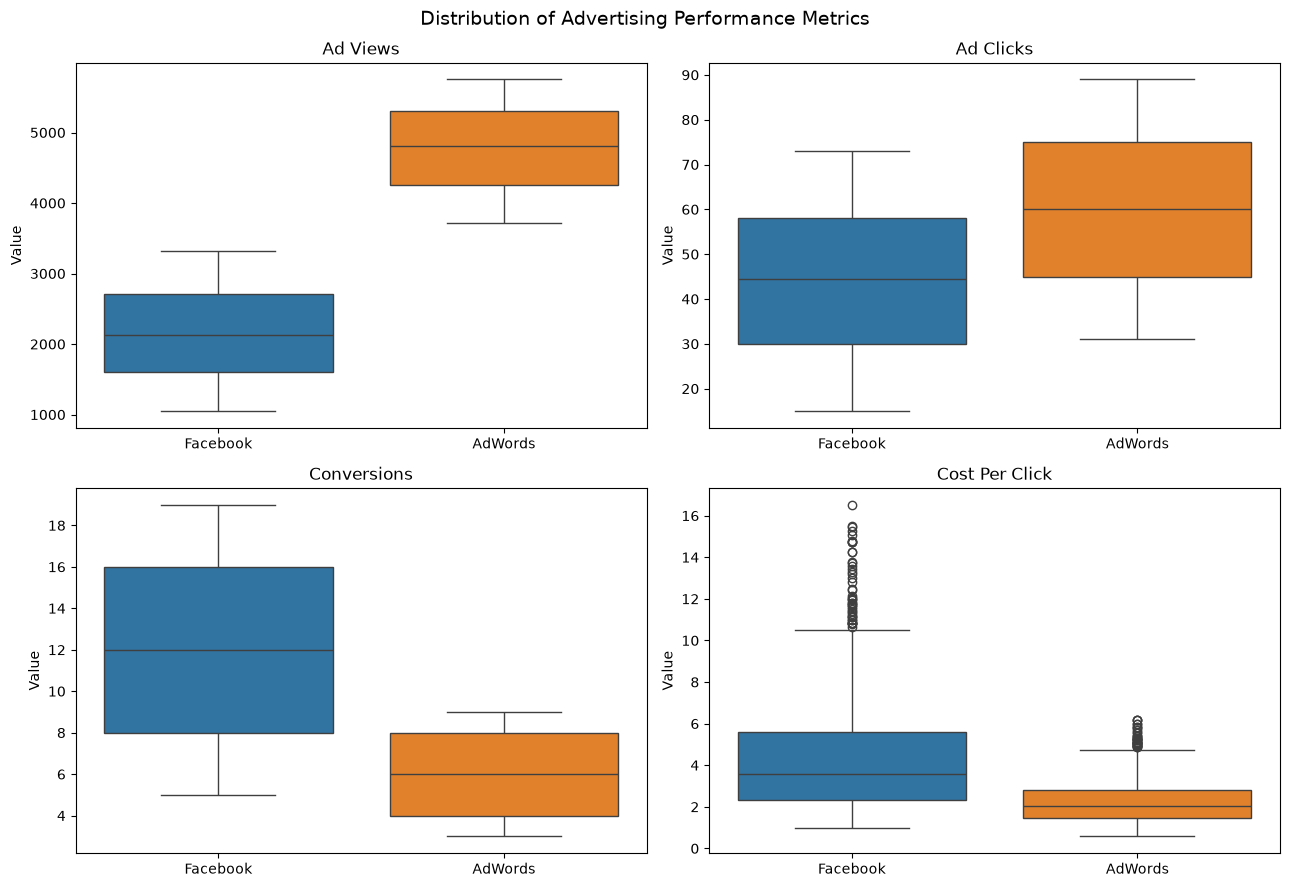

In [19]:
# DISTRIBUTION ANALYSIS
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metrics = [
    ("facebook_ad_views", "adword_ad_views", "Ad Views"),
    ("facebook_ad_clicks", "adword_ad_clicks", "Ad Clicks"),
    ("facebook_ad_conversions", "adword_ad_conversions", "Conversions"),
    ("facebook_cost_per_click", "adword_cost_per_click", "Cost Per Click")
]

for ax, (fb, aw, title) in zip(axes.flatten(), metrics):
    sns.boxplot(
        data=pd.DataFrame({
            "Facebook": df_analysis[fb],
            "AdWords": df_analysis[aw]
        }),
        ax=ax
    )
    ax.set_title(title)
    ax.set_ylabel("Value")

plt.suptitle("Distribution of Advertising Performance Metrics", fontsize=14)
plt.tight_layout()
plt.show()

**Key Findings:**

- Google AdWords demonstrates higher median ad views and clicks.
- Facebook Ads records a higher median number of conversions.
- Facebook Ads has a higher median cost per click than Google AdWords.
- Both platforms contain potential CPC outliers, with greater variation in Facebook CPC.
- The distributions indicate different strengths in reach, engagement, conversion performance and cost efficiency.

*Note: Boxplots identify distribution patterns and potential outliers. Unusual observations have been retained for further analysis.*

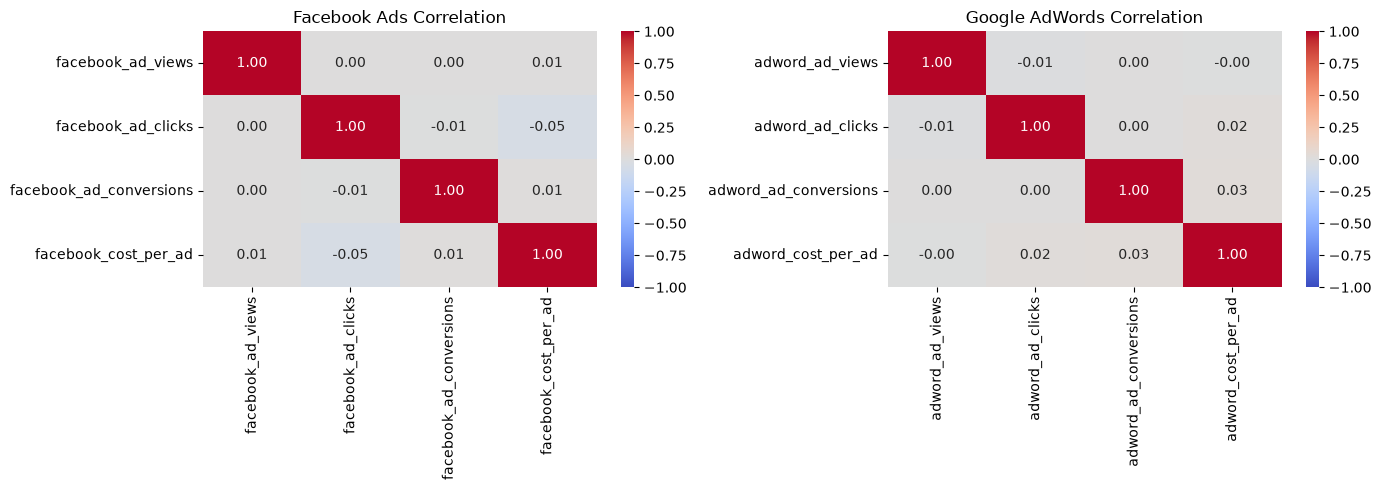

In [20]:
# CORRELATION ANALYSIS
import matplotlib.pyplot as plt
import seaborn as sns
fb_cols = [
    "facebook_ad_views",
    "facebook_ad_clicks",
    "facebook_ad_conversions",
    "facebook_cost_per_ad"
]

aw_cols = [
    "adword_ad_views",
    "adword_ad_clicks",
    "adword_ad_conversions",
    "adword_cost_per_ad"
]

fb_corr = df_analysis[fb_cols].corr()
aw_corr = df_analysis[aw_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    fb_corr, annot=True, cmap="coolwarm",
    fmt=".2f", vmin=-1, vmax=1, ax=axes[0]
)
axes[0].set_title("Facebook Ads Correlation")

sns.heatmap(
    aw_corr, annot=True, cmap="coolwarm",
    fmt=".2f", vmin=-1, vmax=1, ax=axes[1]
)
axes[1].set_title("Google AdWords Correlation")

plt.tight_layout()
plt.show()

**Key Findings:**

- Both Facebook Ads and Google AdWords show very weak linear relationships among the selected advertising metrics.
- No meaningful linear association was observed between clicks and conversions in either platform.
- Advertising cost shows negligible correlation with recorded conversions.
- The correlation patterns are broadly similar across both platforms.

*Note: Correlation does not imply causation. These results represent record-level Pearson correlations and should be interpreted cautiously because the dataset's observation structure is not documented.*

## 5. Marketing Performance Analysis

Evaluate the overall performance of Facebook Ads and Google AdWords using aggregate advertising metrics. Compare advertising reach, engagement, conversions and cost efficiency to identify the relative strengths of each platform.

In [21]:
# OVERALL MARKETING PERFORMANCE KPIs

platforms = {
    "Facebook": {
        "views": "facebook_ad_views",
        "clicks": "facebook_ad_clicks",
        "conversions": "facebook_ad_conversions",
        "spend": "facebook_cost_per_ad"
    },
    "AdWords": {
        "views": "adword_ad_views",
        "clicks": "adword_ad_clicks",
        "conversions": "adword_ad_conversions",
        "spend": "adword_cost_per_ad"
    }
}

kpi_results = {}

for platform, cols in platforms.items():
    views = df_analysis[cols["views"]].sum()
    clicks = df_analysis[cols["clicks"]].sum()
    conversions = df_analysis[cols["conversions"]].sum()
    spend = df_analysis[cols["spend"]].sum()

    kpi_results[platform] = {
        "Total Views": views,
        "Total Clicks": clicks,
        "Total Conversions": conversions,
        "Total Ad Spend": spend,
        "CTR (%)": (clicks / views) * 100,
        "Conversion Rate (%)": (conversions / clicks) * 100,
        "CPC": spend / clicks,
        "CPA": spend / conversions,
        "CPM": (spend / views) * 1000
    }

kpi_table = pd.DataFrame(kpi_results).round(2)

display(kpi_table)

,Facebook,AdWords
Total Views,2152031.00,4771438.00
Total Clicks,44196.00,60128.00
Total Conversions,11975.00,5933.00
Total Ad Spend,156610.00,124741.00
CTR (%),2.05,1.26
Conversion Rate (%),27.10,9.87
CPC,3.54,2.07
CPA,13.08,21.02
CPM,72.77,26.14


### 5.2 Visual Comparison of Marketing KPIs

Compare the aggregate marketing performance of Facebook Ads and Google AdWords using bar charts. Visualise CTR, conversion rate, CPC, CPA and CPM to identify differences in engagement, conversion performance and advertising cost efficiency.

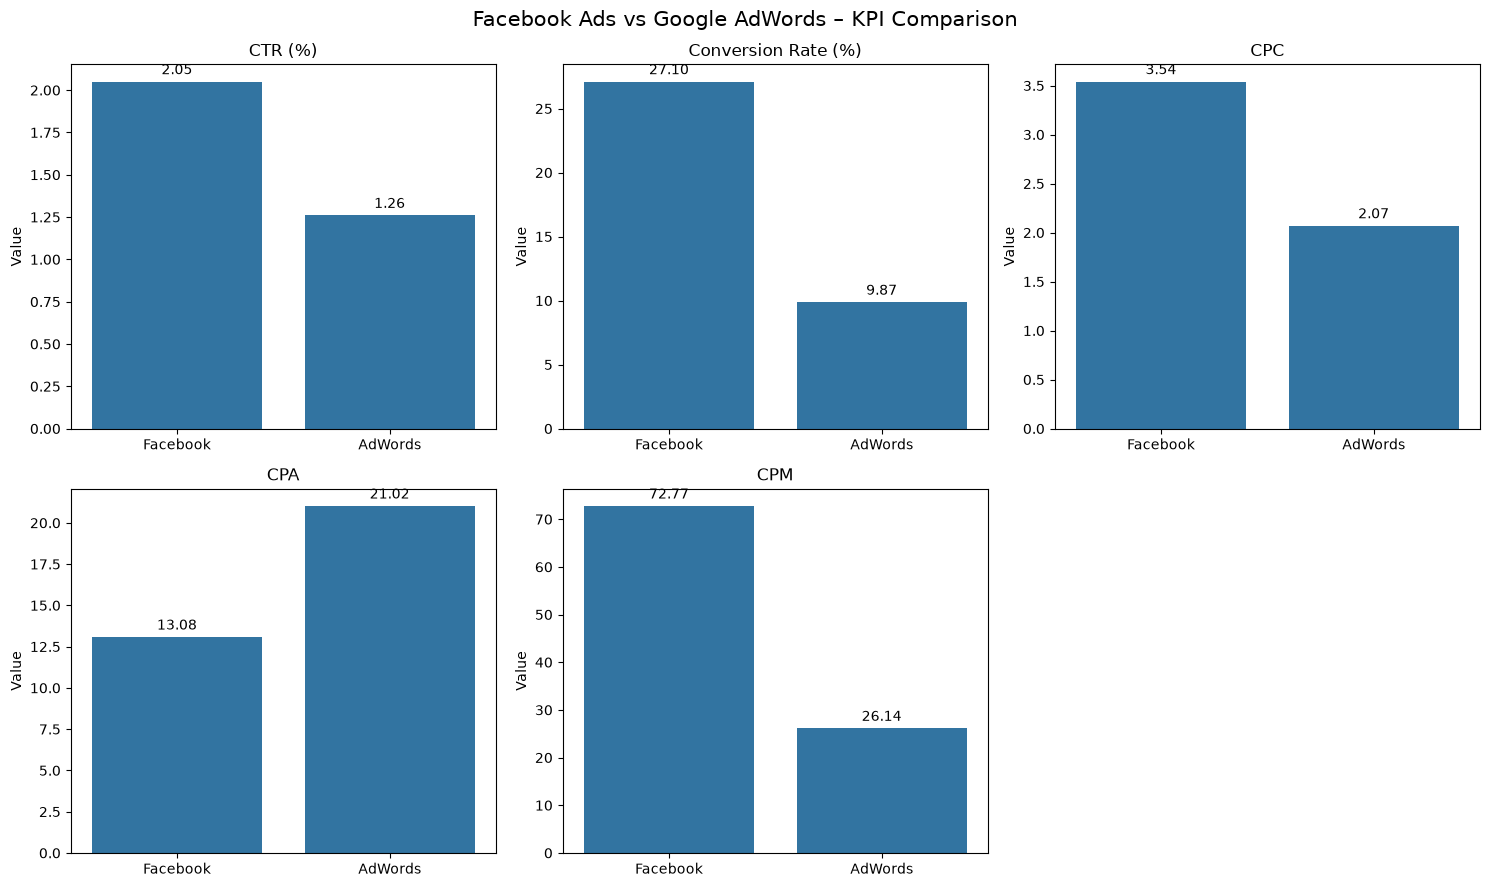

In [22]:
# MARKETING KPI COMPARISON
import matplotlib.pyplot as plt
import seaborn as sns

kpi_metrics = ["CTR (%)", "Conversion Rate (%)", "CPC", "CPA", "CPM"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, metric in zip(axes.flatten(), kpi_metrics):
    values = kpi_table.loc[metric]

    sns.barplot(
        x=values.index,
        y=values.values,
        ax=ax
    )

    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("Value")

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=3)

axes[1, 2].axis("off")

plt.suptitle("Facebook Ads vs Google AdWords – KPI Comparison", fontsize=15)
plt.tight_layout()
plt.show()

### 5.3 Relative Performance Comparison and Campaign Evaluation

Quantify the relative performance differences between Facebook Ads and Google AdWords using percentage comparisons of key marketing KPIs.

Evaluate both platforms based on advertising reach, engagement, conversion performance and cost efficiency to identify their relative strengths.

In [23]:
# RELATIVE PERFORMANCE COMPARISON

comparison = pd.DataFrame(kpi_results)

comparison["Difference (%)"] = (
    (comparison["Facebook"] - comparison["AdWords"]) /
    comparison["AdWords"].abs()
) * 100

display(comparison.round(2))

,Facebook,AdWords,Difference (%)
Total Views,2152031.00,4771438.00,-54.90
Total Clicks,44196.00,60128.00,-26.50
Total Conversions,11975.00,5933.00,101.84
Total Ad Spend,156610.00,124741.00,25.55
CTR (%),2.05,1.26,62.97
Conversion Rate (%),27.10,9.87,174.60
CPC,3.54,2.07,70.81
CPA,13.08,21.02,-37.80
CPM,72.77,26.14,178.36


## 6. Statistical Analysis

Evaluate the differences in advertising performance between Facebook Ads and Google AdWords using paired statistical methods.

The analysis includes date-level aggregation, paired t-tests, Wilcoxon signed-rank tests, effect size estimation and 95% confidence intervals.

*Note: Statistical findings are conditional on the assumption that observations can be aggregated by date and that daily differences are sufficiently independent. The dataset does not establish a randomized A/B testing design.*

In [24]:
# STATISTICAL ANALYSIS
import numpy as np
from scipy import stats

# 1. Aggregate advertising metrics by date
daily = df_analysis.groupby("date_of_campaign").agg(
    fb_views=("facebook_ad_views", "sum"),
    fb_clicks=("facebook_ad_clicks", "sum"),
    fb_conversions=("facebook_ad_conversions", "sum"),
    fb_spend=("facebook_cost_per_ad", "sum"),
    aw_views=("adword_ad_views", "sum"),
    aw_clicks=("adword_ad_clicks", "sum"),
    aw_conversions=("adword_ad_conversions", "sum"),
    aw_spend=("adword_cost_per_ad", "sum")
)

# 2. Calculate daily KPIs
daily["fb_ctr"] = daily["fb_clicks"] / daily["fb_views"] * 100
daily["aw_ctr"] = daily["aw_clicks"] / daily["aw_views"] * 100

daily["fb_cvr"] = daily["fb_conversions"] / daily["fb_clicks"] * 100
daily["aw_cvr"] = daily["aw_conversions"] / daily["aw_clicks"] * 100

daily["fb_cpc"] = daily["fb_spend"] / daily["fb_clicks"]
daily["aw_cpc"] = daily["aw_spend"] / daily["aw_clicks"]

daily["fb_cpa"] = daily["fb_spend"] / daily["fb_conversions"]
daily["aw_cpa"] = daily["aw_spend"] / daily["aw_conversions"]

# 3. Prepare matched observations
daily = daily.replace([np.inf, -np.inf], np.nan).dropna()

# 4. Define metrics for paired comparison
metrics = {
    "CTR": ("fb_ctr", "aw_ctr"),
    "Conversion Rate": ("fb_cvr", "aw_cvr"),
    "CPC": ("fb_cpc", "aw_cpc"),
    "CPA": ("fb_cpa", "aw_cpa")
}

results = []

# 5. Perform statistical tests
for metric, (fb_col, aw_col) in metrics.items():

    fb = daily[fb_col]
    aw = daily[aw_col]

    diff = fb - aw
    n = len(diff)

    # Paired t-test
    t_stat, t_pvalue = stats.ttest_rel(fb, aw)

    # Wilcoxon signed-rank test
    w_stat, w_pvalue = stats.wilcoxon(fb, aw)

    # Mean difference
    mean_diff = diff.mean()

    # 95% confidence interval
    se = stats.sem(diff)

    ci_lower, ci_upper = stats.t.interval(
        confidence=0.95,
        df=n - 1,
        loc=mean_diff,
        scale=se
    )

    # Cohen's dz effect size
    effect_size = mean_diff / diff.std(ddof=1)

    results.append({
        "Metric": metric,
        "Matched Dates": n,
        "Mean Difference (FB - AW)": mean_diff,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "Cohen's dz": effect_size,
        "Paired t-test p-value": t_pvalue,
        "Wilcoxon p-value": w_pvalue
    })

# 6. Create results table
stat_results = pd.DataFrame(results).set_index("Metric")

# 7. Format p-values
for col in ["Paired t-test p-value", "Wilcoxon p-value"]:
    stat_results[col] = stat_results[col].apply(
        lambda p: "<0.001" if p < 0.001 else f"{p:.4f}"
    )

# 8. Display validation and results
print("STATISTICAL ANALYSIS SUMMARY")
print("-" * 55)
print(f"Unique Campaign Dates: {df_analysis['date_of_campaign'].nunique()}")
print(f"Matched Dates Analysed: {len(daily)}")
print(f"Date Range: {daily.index.min().date()} to {daily.index.max().date()}")

print("\nPAIRED STATISTICAL TEST RESULTS")
print("-" * 55)

display(stat_results.round(4))

STATISTICAL ANALYSIS SUMMARY
-------------------------------------------------------
Unique Campaign Dates: 658
Matched Dates Analysed: 658
Date Range: 2021-12-22 to 2024-12-20

PAIRED STATISTICAL TEST RESULTS
-------------------------------------------------------


,Matched Dates,Mean Difference (FB - AW),95% CI Lower,95% CI Upper,Cohen's dz,Paired t-test p-value,Wilcoxon p-value
Metric,,,,,,,
CTR,658,0.9379,0.8533,1.0225,0.8484,<0.001,<0.001
Conversion Rate,658,21.4133,19.9622,22.8644,1.1296,<0.001,<0.001
CPC,658,2.0018,1.8002,2.2034,0.7601,<0.001,<0.001
CPA,658,-8.4980,-9.5177,-7.4782,-0.6379,<0.001,<0.001


## 7. Time-Based Analysis

Analyse advertising performance over time to identify monthly trends, variations and patterns across Facebook Ads and Google AdWords.

### 7.1 Monthly Advertising Performance Trends

Examine monthly advertising views, clicks and conversions to understand how reach, traffic generation and recorded conversions change over time across both platforms.

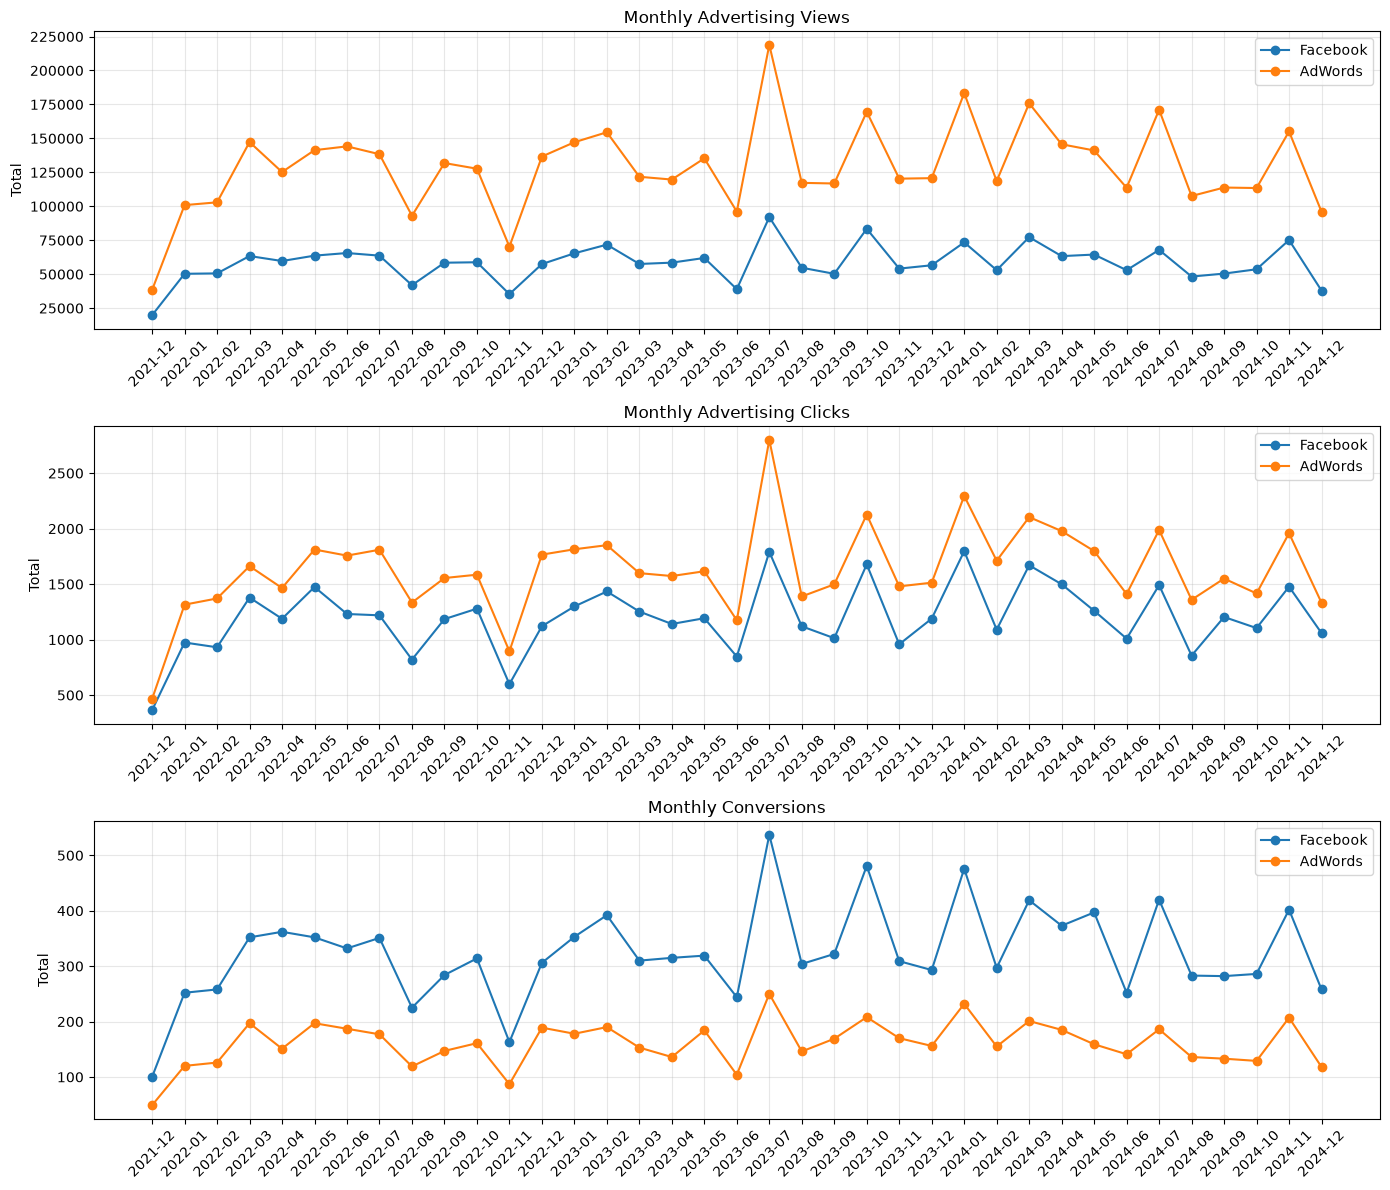

In [25]:
# MONTHLY ADVERTISING PERFORMANCE

monthly = df_analysis.groupby("year_month").agg(
    fb_views=("facebook_ad_views", "sum"),
    aw_views=("adword_ad_views", "sum"),
    fb_clicks=("facebook_ad_clicks", "sum"),
    aw_clicks=("adword_ad_clicks", "sum"),
    fb_conversions=("facebook_ad_conversions", "sum"),
    aw_conversions=("adword_ad_conversions", "sum")
)

monthly.index = monthly.index.astype(str)

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

metrics = [
    ("fb_views", "aw_views", "Monthly Advertising Views"),
    ("fb_clicks", "aw_clicks", "Monthly Advertising Clicks"),
    ("fb_conversions", "aw_conversions", "Monthly Conversions")
]

for ax, (fb, aw, title) in zip(axes, metrics):
    ax.plot(monthly.index, monthly[fb], label="Facebook", marker="o")
    ax.plot(monthly.index, monthly[aw], label="AdWords", marker="o")
    ax.set_title(title)
    ax.set_ylabel("Total")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Key Findings:**

- Google AdWords consistently generates higher monthly advertising views than Facebook Ads.
- Google AdWords generally records higher monthly clicks.
- Facebook Ads consistently records higher monthly conversions.
- Both platforms experience noticeable monthly fluctuations, with some prominent peaks during 2023 and 2024.
- The monthly trends reinforce the differences observed in the aggregate marketing performance analysis.

*Note: Monthly figures represent aggregated totals. Changes in the number of observations per month can influence monthly totals and should be considered when interpreting trends.*

### 7.2 Monthly Conversion and Cost Trends

Analyse monthly CTR, conversion rate, cost per click (CPC), and cost per acquisition (CPA) for Facebook Ads and Google AdWords.

Calculate monthly KPIs using aggregated monthly totals to examine changes in engagement, conversion performance and advertising cost efficiency over time.

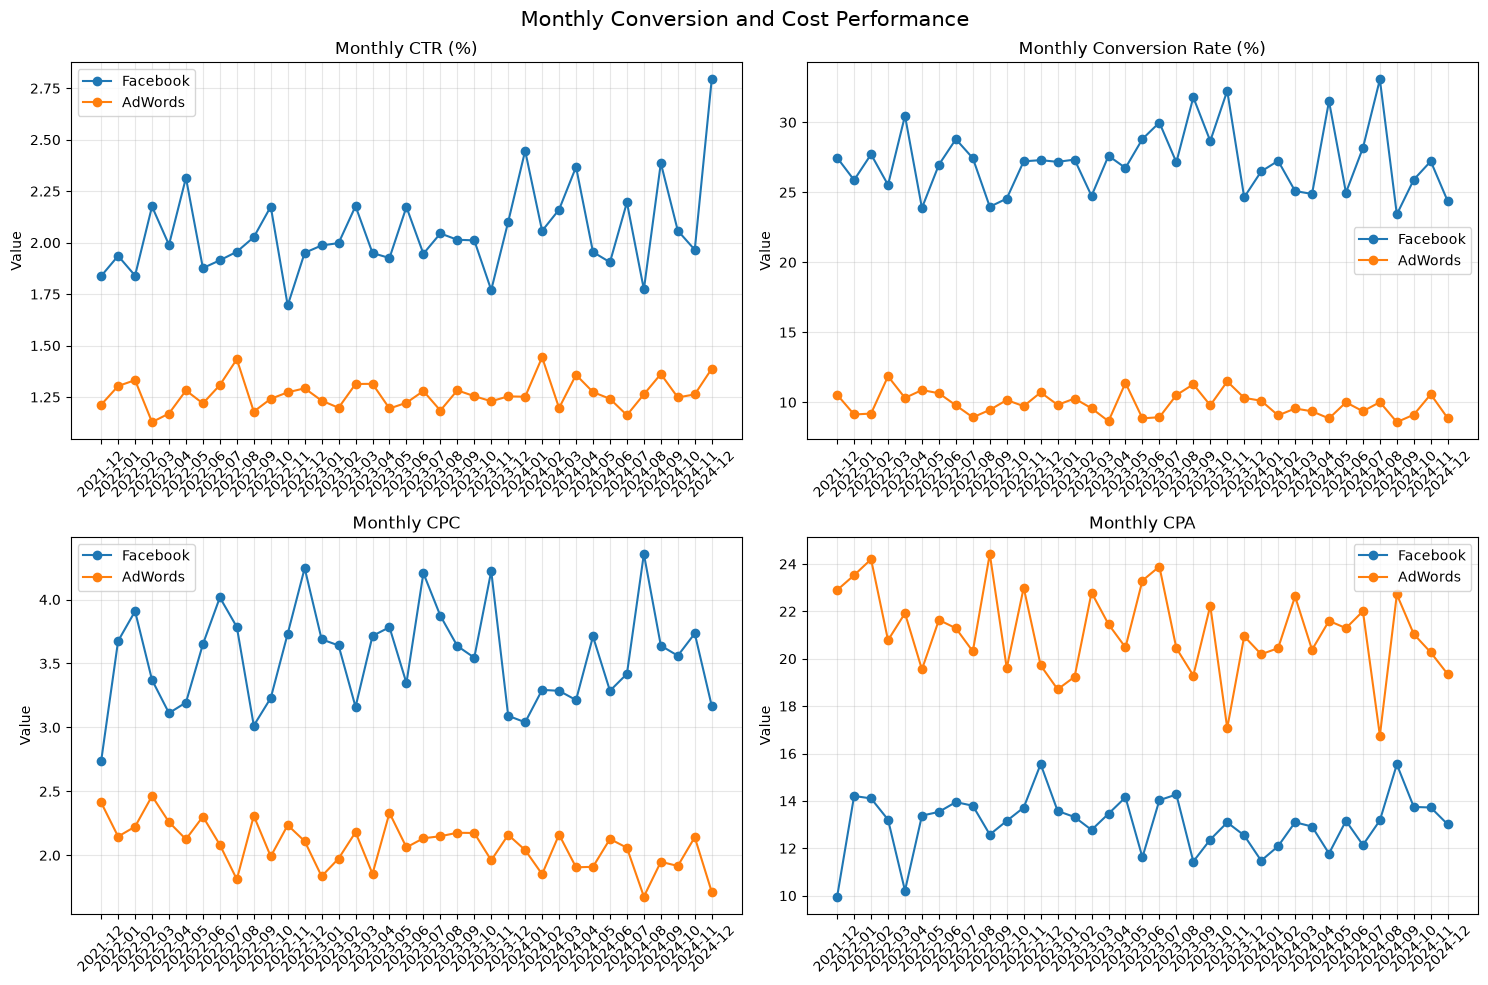

In [26]:
# MONTHLY CONVERSION AND COST ANALYSIS

monthly_kpis = df_analysis.groupby("year_month").agg(
    fb_views=("facebook_ad_views", "sum"),
    fb_clicks=("facebook_ad_clicks", "sum"),
    fb_conversions=("facebook_ad_conversions", "sum"),
    fb_spend=("facebook_cost_per_ad", "sum"),
    aw_views=("adword_ad_views", "sum"),
    aw_clicks=("adword_ad_clicks", "sum"),
    aw_conversions=("adword_ad_conversions", "sum"),
    aw_spend=("adword_cost_per_ad", "sum")
)

# Calculate monthly KPIs
for platform in ["fb", "aw"]:
    monthly_kpis[f"{platform}_ctr"] = (
        monthly_kpis[f"{platform}_clicks"] /
        monthly_kpis[f"{platform}_views"] * 100
    )

    monthly_kpis[f"{platform}_cvr"] = (
        monthly_kpis[f"{platform}_conversions"] /
        monthly_kpis[f"{platform}_clicks"] * 100
    )

    monthly_kpis[f"{platform}_cpc"] = (
        monthly_kpis[f"{platform}_spend"] /
        monthly_kpis[f"{platform}_clicks"]
    )

    monthly_kpis[f"{platform}_cpa"] = (
        monthly_kpis[f"{platform}_spend"] /
        monthly_kpis[f"{platform}_conversions"]
    )

# Prepare monthly labels
monthly_kpis.index = monthly_kpis.index.astype(str)

# Plot monthly KPI trends
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

metrics = [
    ("fb_ctr", "aw_ctr", "Monthly CTR (%)"),
    ("fb_cvr", "aw_cvr", "Monthly Conversion Rate (%)"),
    ("fb_cpc", "aw_cpc", "Monthly CPC"),
    ("fb_cpa", "aw_cpa", "Monthly CPA")
]

for ax, (fb, aw, title) in zip(axes.flatten(), metrics):
    ax.plot(monthly_kpis.index, monthly_kpis[fb],
            marker="o", label="Facebook")
    ax.plot(monthly_kpis.index, monthly_kpis[aw],
            marker="o", label="AdWords")

    ax.set_title(title)
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Monthly Conversion and Cost Performance", fontsize=15)
plt.tight_layout()
plt.show()

**Key Findings:**

- Facebook Ads consistently demonstrates higher monthly CTR and conversion rates than Google AdWords.
- Google AdWords maintains a lower monthly CPC throughout the analysis period.
- Facebook Ads consistently records a lower CPA, indicating lower cost per recorded conversion.
- Facebook shows greater variation in CPC, while AdWords demonstrates comparatively stable click costs.
- The monthly trends reinforce the aggregate KPI findings, with Facebook showing stronger recorded conversion efficiency and AdWords showing stronger traffic cost efficiency.

*Note: Monthly KPIs are calculated using aggregated totals. Monthly observations may vary in volume, and the results are observational rather than causal.*

### 7.3 Monthly Platform Performance Comparison

Compare monthly advertising expenditure and recorded conversions across Facebook Ads and Google AdWords. Examine how changes in advertising spend correspond with conversion volumes and evaluate monthly cost efficiency using CPA.

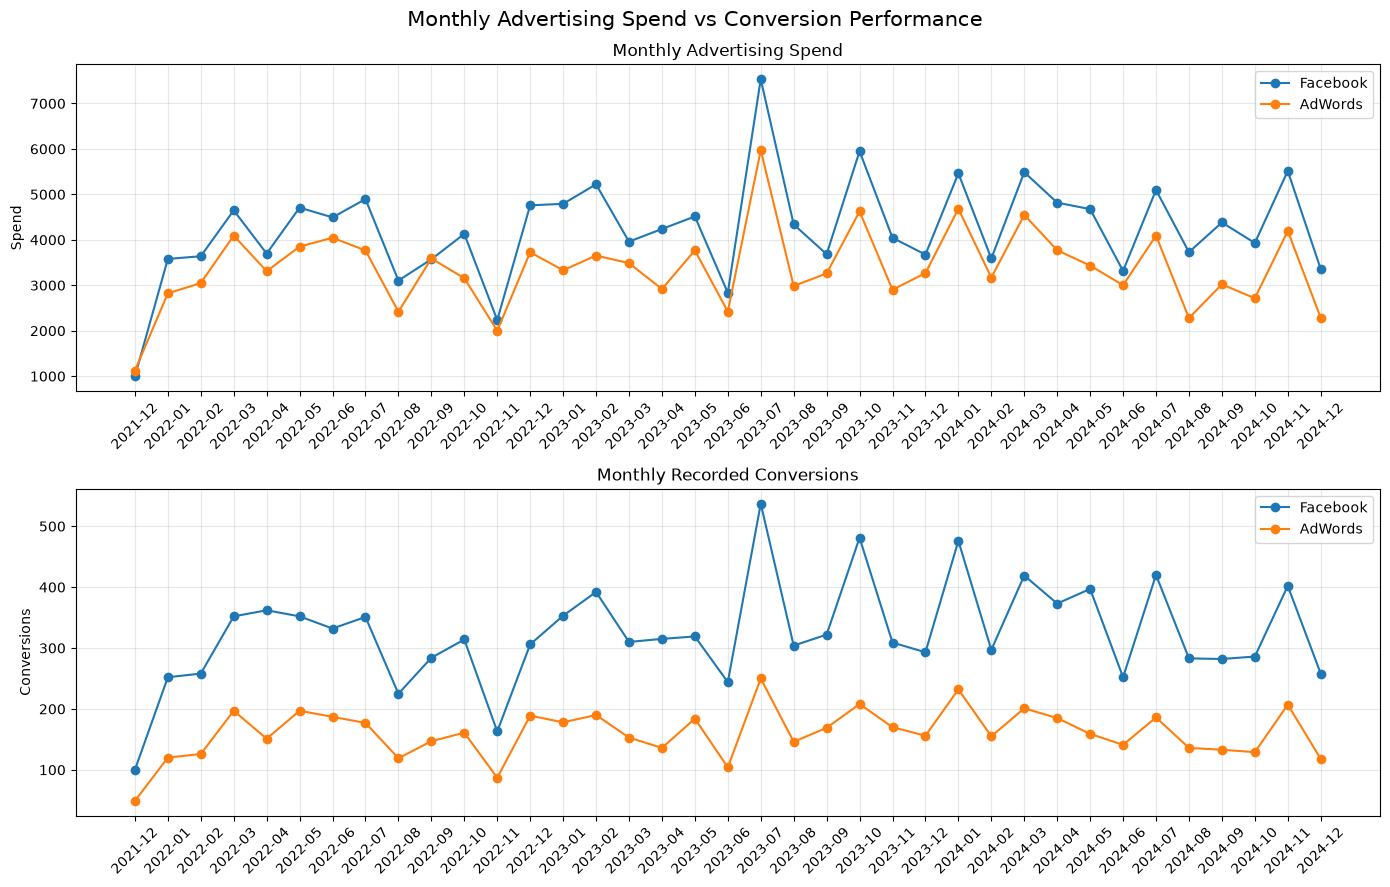

In [27]:
# MONTHLY PLATFORM PERFORMANCE COMPARISON

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Monthly advertising spend
axes[0].plot(
    monthly_kpis.index,
    monthly_kpis["fb_spend"],
    marker="o",
    label="Facebook"
)
axes[0].plot(
    monthly_kpis.index,
    monthly_kpis["aw_spend"],
    marker="o",
    label="AdWords"
)
axes[0].set_title("Monthly Advertising Spend")
axes[0].set_ylabel("Spend")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Monthly recorded conversions
axes[1].plot(
    monthly_kpis.index,
    monthly_kpis["fb_conversions"],
    marker="o",
    label="Facebook"
)
axes[1].plot(
    monthly_kpis.index,
    monthly_kpis["aw_conversions"],
    marker="o",
    label="AdWords"
)
axes[1].set_title("Monthly Recorded Conversions")
axes[1].set_ylabel("Conversions")
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Monthly Advertising Spend vs Conversion Performance", fontsize=15)
plt.tight_layout()
plt.show()

**Key Findings:**

- Facebook Ads generally records higher monthly advertising expenditure than Google AdWords.
- Facebook Ads consistently generates more recorded conversions across the observed months.
- Both platforms experience a noticeable increase in advertising spend and conversions during June 2023.
- Higher advertising expenditure coincides with higher conversion volumes during some periods, although this does not establish a causal relationship.
- The monthly comparison reinforces Facebook's stronger recorded conversion volume, while AdWords operates with comparatively lower advertising expenditure.

*Note: Monthly advertising expenditure and conversion figures are aggregated totals. Differences in monthly observation volume and the undocumented campaign structure should be considered when interpreting these trends.*

## 8. Final Insights and Recommendations

**Key Findings:**

- Google AdWords generated higher advertising reach and click volume.
- Facebook Ads achieved higher CTR and conversion rates.
- Facebook Ads generated approximately 102% more recorded conversions.
- Google AdWords had lower CPC and CPM.
- Facebook Ads achieved approximately 38% lower CPA.
- Statistical comparisons showed significant differences across all four evaluated KPIs.
- Monthly trends consistently showed higher recorded conversion volumes for Facebook Ads.
- Both platforms demonstrated different strengths in advertising performance and cost efficiency.